# Lab 1: Vacuum Cleaner Agent (4 rooms)
Environment (Anaconda): `conda create -n ailab python=3.11 numpy matplotlib jupyter`, then `conda activate ailab` and `jupyter notebook`.

Run cells top to bottom with **Shift+Enter**.

**PEAS:** performance = +1 per clean room per step; environment = 4 rooms with random dirt; actuators = Left/Right/Suck/NoOp; sensors = (position, status).

## Cell 1: Setup (ready-made libraries)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_ROOMS = 4     # number of rooms
STEPS = 50      # steps in one run
RUNS = 100      # number of experiments per agent

## Cell 2: One simple function

In [2]:
def simulate(agent, seed):
    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5               # True = dirty room
    known_clean = np.zeros(N_ROOMS, dtype=bool)    # memory of the "model" agent
    pos, direction, score = 0, 1, 0

    for step in range(STEPS):
        known_clean[pos] = not dirt[pos]

        # 1) choose an action
        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            if pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        # 2) apply the action
        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        score += (~dirt).sum()                     # +1 for each clean room
    return int(score)

## Cell 3: Quick test of the 3 agents

In [3]:
for agent in ["random", "reflex", "model"]:
    print(agent, simulate(agent, seed=1))

random 184
reflex 190
model 198


## Cell 4: 100 experiments (pandas)

In [4]:
rows = []
for agent in ["random", "reflex", "model"]:
    for seed in range(RUNS):
        rows.append({"agent": agent, "score": simulate(agent, seed)})

df = pd.DataFrame(rows)
print(df.head())

    agent  score
0  random    178
1  random    184
2  random    142
3  random    157
4  random    195


## Cell 5: Summary table

In [5]:
summary = df.groupby("agent")["score"].agg(["mean", "std"]).round(1)
print(summary)

         mean   std
agent              
model   195.7   2.9
random  167.2  24.9
reflex  188.5  10.9


## Cell 6: Plot

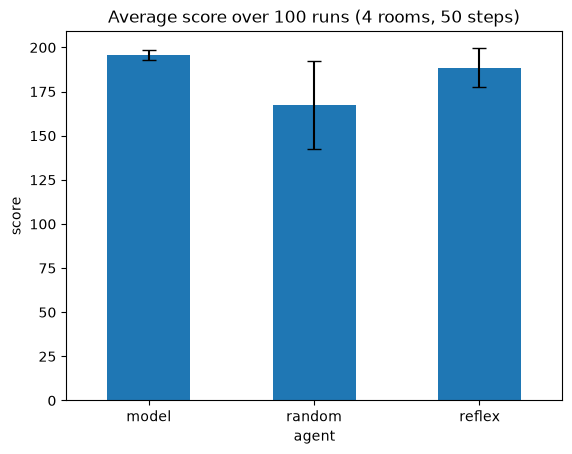

In [6]:
summary["mean"].plot(kind="bar", yerr=summary["std"], capsize=5)
plt.title("Average score over 100 runs (4 rooms, 50 steps)")
plt.ylabel("score")
plt.xticks(rotation=0)
plt.show()

## Analysis questions
1. Why is the random agent weak?
2. Why does the model-based agent stop?
3. What if dirt reappears with probability p?

## Challenges
2D grid, noisy sensor, energy cost, dirt reappearing.

## Cell 7: Record frames for animation

This function follows the same agent rules as `simulate`, but saves the room state after every step so it can be animated.

In [7]:
def record(agent, seed=1):
    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5
    known_clean = np.zeros(N_ROOMS, dtype=bool)
    pos, direction, score = 0, 1, 0
    frames = [(pos, dirt.copy(), "Start", score)]

    for step in range(STEPS):
        known_clean[pos] = not dirt[pos]

        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            if pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        score += int((~dirt).sum())
        frames.append((pos, dirt.copy(), action, score))

    return frames


## Cell 8: Animate the three agents

Each row shows one agent moving through the same initial room layout. Red rooms are dirty; green rooms are clean.

In [8]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

names = ["random", "reflex", "model"]
runs = [record(agent, seed=1) for agent in names]

fig, axes = plt.subplots(3, 1, figsize=(7, 4.5), dpi=80)

def draw(t):
    for ax, name, frames in zip(axes, names, runs):
        pos, dirt_state, action, score = frames[t]
        ax.clear()
        ax.set_xlim(0, N_ROOMS)
        ax.set_ylim(0, 1)
        ax.axis("off")

        for room in range(N_ROOMS):
            color = "#fecaca" if dirt_state[room] else "#bbf7d0"
            ax.add_patch(plt.Rectangle((room + 0.05, 0.05), 0.9, 0.9, color=color))
            if dirt_state[room]:
                ax.add_patch(plt.Circle((room + 0.5, 0.35), 0.13, color="#38bdf8"))

        ax.text(pos + 0.5, 0.68, "R", fontsize=19, fontweight="bold",
                ha="center", va="center")
        ax.set_title(f"{name} | step {t} | action: {action} | score: {score}", fontsize=9)

anim = FuncAnimation(fig, draw, frames=len(runs[0]), interval=250, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())


## Cell 9: Animated bar chart of average scores

This animation grows the bars toward the final mean scores computed in Cell 5.

In [9]:
fig2, ax2 = plt.subplots(figsize=(6, 3.5), dpi=80)
final = summary["mean"]

def grow(k):
    ax2.clear()
    ax2.set_ylim(0, max(210, float(final.max()) * 1.15))
    ax2.set_title("Average score over 100 runs")
    ax2.set_ylabel("Score")
    values = final.values * (k + 1) / 20
    bars = ax2.bar(final.index, values, color=["#ec4899", "#4f46e5", "#f59e0b"])
    for bar, value in zip(bars, values):
        ax2.text(bar.get_x() + bar.get_width() / 2, value + 2,
                 f"{value:.1f}", ha="center", va="bottom")
    ax2.set_xticks(range(len(final.index)), final.index, rotation=0)

anim2 = FuncAnimation(fig2, grow, frames=20, interval=120, repeat=False)
plt.close(fig2)
HTML(anim2.to_jshtml())



## Challenge: Dirt Reappearing (کثیفی مجدد محیط)

در این توسعه، پس از هر گام ممکن است بعضی از اتاق‌های تمیز دوباره کثیف شوند. پارامتر `p_reappear` احتمال کثیف شدن مجدد هر اتاق تمیز در هر گام را مشخص می‌کند.

در محیط پویا، عامل مدل‌محور نمی‌تواند صرفاً به این دلیل که همه اتاق‌ها را یک‌بار تمیز دیده است متوقف شود؛ باید گشت‌زنی را ادامه دهد و وضعیت اتاق‌ها را دوباره بررسی کند.

**ارتباط با پروژه پیشنهاد فیلم و کتاب:** کثیف شدن مجدد اتاق‌ها مشابه اضافه شدن فیلم‌ها و کتاب‌های جدید یا تغییر علایق کاربر است. سیستم پیشنهاددهنده نیز باید با تغییر محیط و دریافت بازخورد جدید، پیشنهادهای خود را به‌روزرسانی کند.


In [10]:
def simulate_dynamic(agent, seed, p_reappear=0.10):
    """Run one vacuum-agent experiment in an environment where dirt can reappear."""
    if not 0 <= p_reappear <= 1:
        raise ValueError("p_reappear must be between 0 and 1")

    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5
    known_clean = np.zeros(N_ROOMS, dtype=bool)
    pos, direction, score = 0, 1, 0

    for step in range(STEPS):
        known_clean[pos] = not dirt[pos]

        # 1) Choose an action
        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif agent == "model":
            if p_reappear == 0 and known_clean.all():
                action = "NoOp"
            else:
                if pos == N_ROOMS - 1:
                    direction = -1
                if pos == 0:
                    direction = 1
                action = "Right" if direction == 1 else "Left"
        else:
            raise ValueError("agent must be 'random', 'reflex', or 'model'")

        # 2) Apply the action
        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        # 3) Some clean rooms may become dirty again
        if p_reappear > 0:
            reappeared = (~dirt) & (rng.random(N_ROOMS) < p_reappear)
            dirt[reappeared] = True
            known_clean[reappeared] = False

        # Keep the same performance measure as the original exercise
        score += int((~dirt).sum())

    return score

# Quick test of the dynamic version
for agent_name in ["random", "reflex", "model"]:
    print(agent_name, simulate_dynamic(agent_name, seed=1, p_reappear=0.10))


random 80
reflex 149
model 158


## Experiment: Effect of the reappearing-dirt probability

برای هر احتمال، هر عامل روی ۱۰۰ اجرای مستقل آزمایش می‌شود. امتیاز همچنان مجموع تعداد اتاق‌های تمیز در طول گام‌هاست؛ بنابراین امتیاز بالاتر نشان‌دهنده تمیز ماندن تعداد بیشتری از اتاق‌ها در طول زمان است.


,p_reappear,agent,mean_score,std_score
0,0.00,random,167.25,24.85
1,0.00,reflex,188.50,10.85
2,0.00,model,195.74,2.91
3,0.05,random,104.68,24.66
4,0.05,reflex,149.32,20.70
5,0.05,model,168.93,10.91
6,0.10,random,75.93,21.16
7,0.10,reflex,119.03,18.62
8,0.10,model,140.36,14.81
9,0.20,random,44.32,12.63


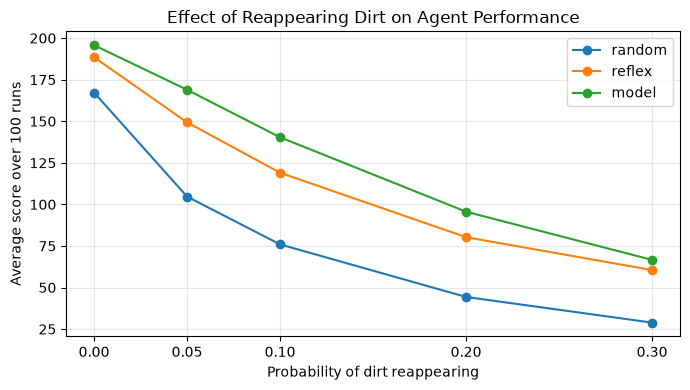

In [11]:
REAPPEAR_PROBS = [0.00, 0.05, 0.10, 0.20, 0.30]
DYNAMIC_RUNS = 100
dynamic_rows = []

for probability in REAPPEAR_PROBS:
    for agent_name in ["random", "reflex", "model"]:
        scores = [
            simulate_dynamic(agent_name, seed=seed, p_reappear=probability)
            for seed in range(DYNAMIC_RUNS)
        ]
        dynamic_rows.append({
            "p_reappear": probability,
            "agent": agent_name,
            "mean_score": np.mean(scores),
            "std_score": np.std(scores, ddof=1)
        })

dynamic_summary = pd.DataFrame(dynamic_rows)
display(dynamic_summary.round(2))

plt.figure(figsize=(7, 4))
for agent_name in ["random", "reflex", "model"]:
    agent_data = dynamic_summary[dynamic_summary["agent"] == agent_name]
    plt.plot(agent_data["p_reappear"], agent_data["mean_score"], marker="o", label=agent_name)

plt.title("Effect of Reappearing Dirt on Agent Performance")
plt.xlabel("Probability of dirt reappearing")
plt.ylabel("Average score over 100 runs")
plt.xticks(REAPPEAR_PROBS)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Interpretation and connection to the recommendation project

1. با افزایش `p_reappear`، محیط سریع‌تر تغییر می‌کند و نگه داشتن همه اتاق‌ها در وضعیت تمیز دشوارتر می‌شود.
2. عامل مدل‌محور در حالت ثابت (`p_reappear = 0`) پس از تمیز و بررسی کردن همه اتاق‌ها می‌تواند متوقف شود؛ اما در محیط پویا باید گشت‌زنی را ادامه دهد.
3. در پروژه پیشنهاد فیلم و کتاب، اضافه شدن عنوان‌های جدید یا تغییر علاقه کاربر معادل تغییر وضعیت محیط است. سیستم باید داده‌های جدید و بازخوردهای تازه را دریافت کند و پیشنهادها را دوباره محاسبه کند.

**محدودیت مدل:** این تمرین فقط سازگاری عامل با تغییر محیط را شبیه‌سازی می‌کند و به‌تنهایی دقت یک الگوریتم پیشنهاددهنده را اندازه‌گیری نمی‌کند. معیارهای دقت پیشنهاد باید جداگانه روی داده‌های فیلم و کتاب سنجیده شوند.
